# Credit Card Fraud: Exploratory Data Analysis
**AI assistant used:** Claude Sonnet 5.5

This notebook explores a dataset of credit card transactions to understand what separates fraudulent transactions from legitimate ones. I used an AI assistant to generate the code, and the prompts I gave it appear in the cells throughout the notebook. The focus here is on exploratory data analysis (EDA): loading and inspecting the data, cleaning it, and visualizing it one variable at a time and then in relation to fraud.

## Data Context

Each row is one credit card transaction. The dataset has the following columns:

| Feature | Description |
|---|---|
| distance_from_home | Distance from the cardholder's home where the transaction took place |
| distance_from_last_transaction | Distance from the location of the previous transaction |
| ratio_to_median_purchase_price | Purchase amount divided by the cardholder's median purchase amount |
| repeat_retailer | 1 if the transaction was at a retailer used before, 0 otherwise |
| used_chip | 1 if the card's chip was used, 0 otherwise |
| used_pin_number | 1 if a PIN was used, 0 otherwise |
| online_order | 1 if the transaction was an online order, 0 otherwise |
| fraud | 1 if the transaction was fraudulent, 0 otherwise (the outcome we care about) |


## Load Libraries and Data
We start by importing the libraries for data manipulation (pandas, numpy) and visualization (matplotlib, seaborn), then reading the CSV into a dataframe.

**Prompt:** Ok, you have the file card_transdata.csv, created python code to import the necessary libraries for data manipulation, visualizations. And then read the data as a pandas dataframe and display the first few rows.


**AI:** Claude Sonnet 5.5

In [4]:
# Libraries for data manipulation and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data
transactions_raw_df = pd.read_csv('card_transdata.csv')

# Display the first few rows
transactions_raw_df.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
1,10.829943,0.175592,1.294219,1.0,NaN,0.0,0.0,0
2,5.091079,NaN,0.427715,1.0,0.0,0.0,1.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0


## Initial Inspection
Before changing anything, we look at the size of the raw data, the data types and missing values, and summary statistics. The raw dataframe is kept as `transactions_raw_df` so the original data stays untouched while we work on a cleaned copy.

**Prompt:** Perfect, since this is the raw data we will later be modifying could you make the original variable name something to identify this (like trasactions_raw_df). And afterwards could you print the shape, info, and summary statistics of this raw data.


**AI:** Claude Sonnet 5.5

In [ ]:
# Shape
transactions_raw_df.shape

(999, 8)

In [6]:
# Info
transactions_raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   distance_from_home              999 non-null    float64
 1   distance_from_last_transaction  996 non-null    float64
 2   ratio_to_median_purchase_price  997 non-null    float64
 3   repeat_retailer                 992 non-null    float64
 4   used_chip                       995 non-null    float64
 5   used_pin_number                 997 non-null    float64
 6   online_order                    995 non-null    float64
 7   fraud                           999 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 62.6 KB


In [7]:
# Summary statistics
transactions_raw_df.describe()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
count,999.000000,996.000000,997.000000,992.000000,995.000000,997.000000,995.000000,999.000000
mean,26.876607,5.437319,1.655069,0.892137,0.313568,0.117352,0.673367,0.079079
std,63.899697,35.668094,2.351386,0.310364,0.464176,0.322001,0.469218,0.269997
min,0.104184,0.001448,0.016933,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.990543,0.306441,0.468123,1.000000,0.000000,0.000000,0.000000,0.000000
50%,10.340321,0.958539,0.955504,1.000000,0.000000,0.000000,1.000000,0.000000
75%,25.393952,3.137259,1.922025,1.000000,1.000000,0.000000,1.000000,0.000000
max,965.910612,990.070315,36.074366,1.000000,1.000000,1.000000,1.000000,1.000000


## Data Wrangling
The `info()` output showed that several columns have missing values. We count the nulls in each column, then decide how to handle them.

**Prompt:** Now we need to perform data wrangling. Check the total number of null values by column in our dataset and then drop the rows with null values creating a new trasactions_cleaned_df, printing the shape of this new dataframe and the first few rows.


**AI:** Claude Sonnet 5.5

In [8]:
# Total null values by column
transactions_raw_df.isnull().sum()

distance_from_home                0
distance_from_last_transaction    3
ratio_to_median_purchase_price    2
repeat_retailer                   7
used_chip                         4
used_pin_number                   2
online_order                      4
fraud                             0
dtype: int64

In [9]:
# Drop rows with any null values into a new dataframe
transactions_cleaned_df = transactions_raw_df.dropna()
print(transactions_cleaned_df.shape)


(977, 8)


There are 22 missing values in total, spread across six columns, and each one falls in a different row. Dropping every row with a null removes 22 of 999 rows (about 2%) and leaves 977, so we lose very little data. The class balance is also essentially unchanged (79 fraud cases before, 76 after). Given that, dropping the rows is a reasonable and simple choice. The result is saved as `transactions_cleaned_df`, which the rest of the analysis uses.

In [10]:
transactions_cleaned_df.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0
5,5.586408,13.261073,0.064768,1.0,0.0,0.0,0.0,0
6,3.724019,0.956838,0.278465,1.0,0.0,0.0,1.0,0


   ## Visualize the Data
   We start with single-variable plots to see how each feature is distributed.

**Prompt:** We will now begin visualizing the data. First we will create four countplots with our cleaned dataframe. The first is visualizing the class distribution of fraud. Name this visualization 'Fraud Class Distribution.'

This second countplot is visualizing the pin number distribution, named 'Used Pin Distribution.'

The third is repeat retailer, 'Repeat Retailer Distribution.'

Finally, the last is online orders, 'Online Orders Distribution.'


**AI:** Claude Sonnet 5.5

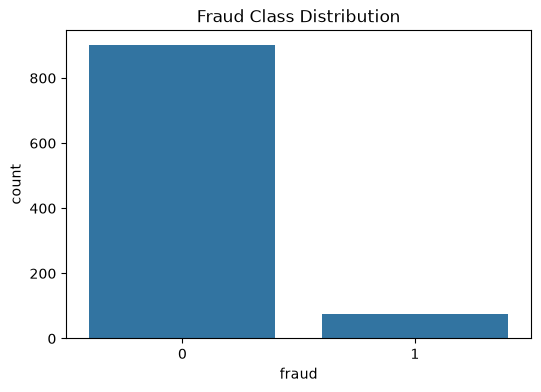

In [11]:
# 1. Fraud Class Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='fraud', data=transactions_cleaned_df)
plt.title('Fraud Class Distribution')
plt.show()

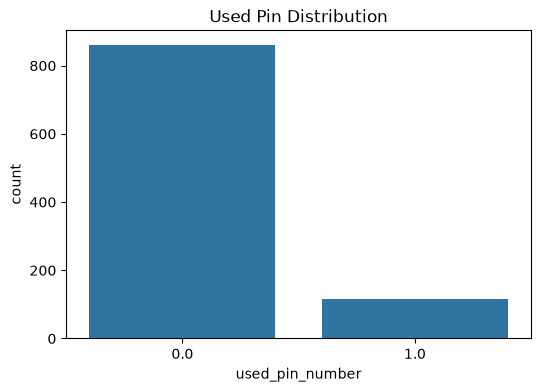

In [12]:
# 2. Used Pin Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='used_pin_number', data=transactions_cleaned_df)
plt.title('Used Pin Distribution')
plt.show()

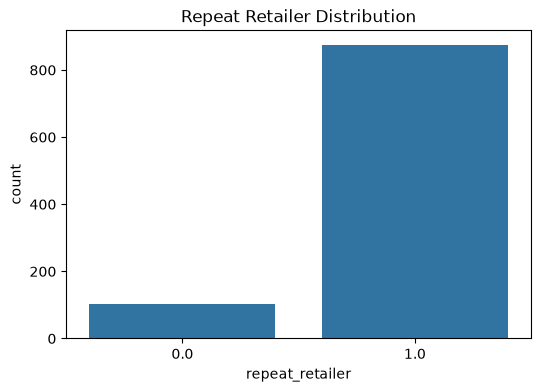

In [13]:
# 3. Repeat Retailer Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='repeat_retailer', data=transactions_cleaned_df)
plt.title('Repeat Retailer Distribution')
plt.show()

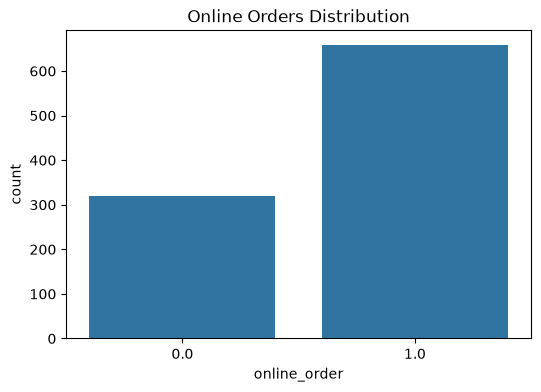

In [14]:
# 4. Online Orders Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='online_order', data=transactions_cleaned_df)
plt.title('Online Orders Distribution')
plt.show()

**Prompt:** Next we want to visualize the distribution of 'ratio_to_median_purchase_price' as a histogram with 30 bins, as 'Ratio to Median Purchase Price Distribution'. Afterwards create another histogram to visualize the distribution of of 'distance_from_home'.


**AI:** Claude Sonnet 5.5

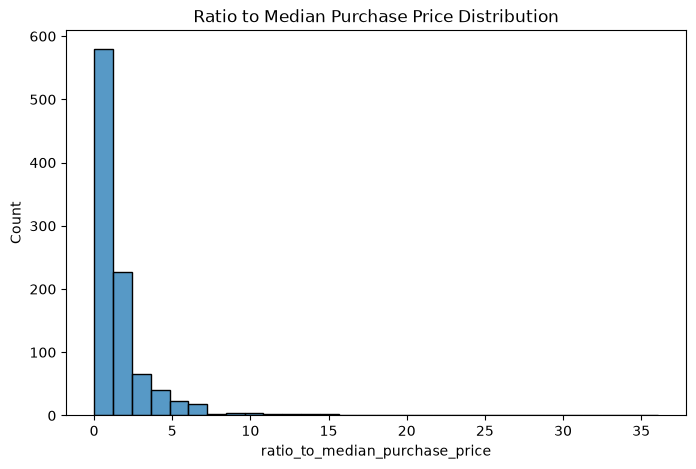

In [15]:
# Ratio to Median Purchase Price Distribution
plt.figure(figsize=(8, 5))
sns.histplot(transactions_cleaned_df['ratio_to_median_purchase_price'], bins=30)
plt.title('Ratio to Median Purchase Price Distribution')
plt.xlabel('ratio_to_median_purchase_price')
plt.show()

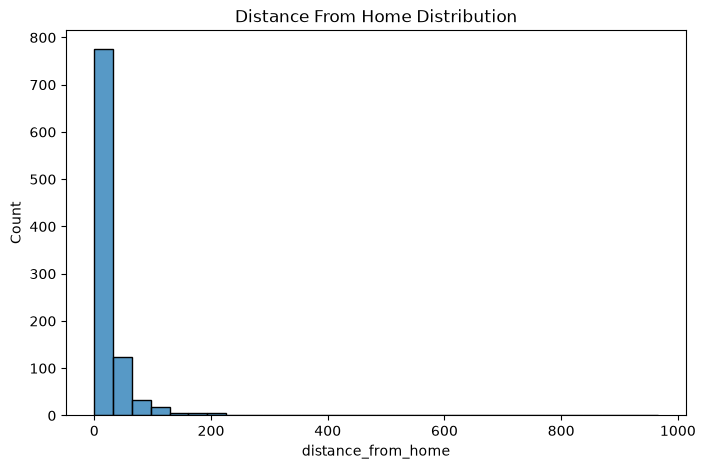

In [16]:
# Distance From Home Distribution
plt.figure(figsize=(8, 5))
sns.histplot(transactions_cleaned_df['distance_from_home'], bins=30)
plt.title('Distance From Home Distribution')
plt.xlabel('distance_from_home')
plt.show()

## Bivariate Visualizations
Single-variable plots tell us what the data looks like overall, but not what is different about fraud. Here we split each feature by fraud status. For each feature there are two views: a count plot (how many transactions) and a stacked percentage plot (what share of each group was fraudulent). The percentage plots matter because fraud is rare, so raw counts alone make small differences hard to see.

**Prompt:** Now we will consider bivariate visualizations. It would be helpful to know how fraudulent and non fraudulent transactions break down each variable.

Create a countplot 'Transactions with PIN vs Fraudulent Transactions' where the hue is the 'fraud' and compare with green and red columns. Create appropriate label names as well.  Then create a percentage plot to show the percentage of fraudulent transactions when a pin was and was not used.


**AI:** Claude Sonnet 5.5

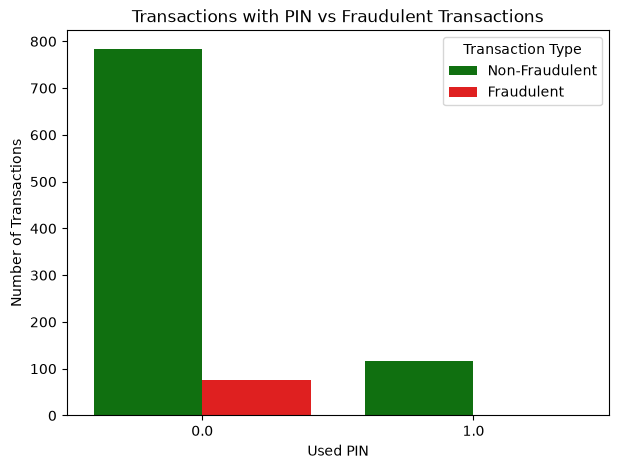

In [26]:
# Transactions with PIN vs Fraudulent Transactions
plt.figure(figsize=(7, 5))
sns.countplot(x='used_pin_number', hue='fraud', data=transactions_cleaned_df,
              palette={0: 'green', 1: 'red'})
plt.title('Transactions with PIN vs Fraudulent Transactions')
plt.xlabel('Used PIN')
plt.ylabel('Number of Transactions')
plt.legend(title='Transaction Type', labels=['Non-Fraudulent', 'Fraudulent'])
plt.show()

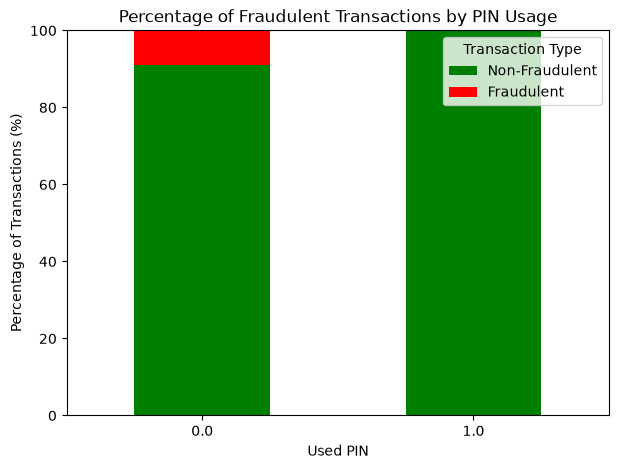

In [25]:
# Percentage of Fraudulent vs Non-Fraudulent Transactions by PIN Usage
pin_fraud_pct = pd.crosstab(transactions_cleaned_df['used_pin_number'],
                            transactions_cleaned_df['fraud'],
                            normalize='index') * 100

pin_fraud_pct.plot(kind='bar', stacked=True, color=['green', 'red'], figsize=(7, 5))
plt.title('Percentage of Fraudulent Transactions by PIN Usage')
plt.xlabel('Used PIN')
plt.ylabel('Percentage of Transactions (%)')
plt.xticks(rotation=0)
plt.legend(title='Transaction Type', labels=['Non-Fraudulent', 'Fraudulent'])
plt.show()

**Prompt:** And repeat this with transactions used with a card chip vs not. And for transactions with online orders.


**AI:** Claude Sonnet 5.5

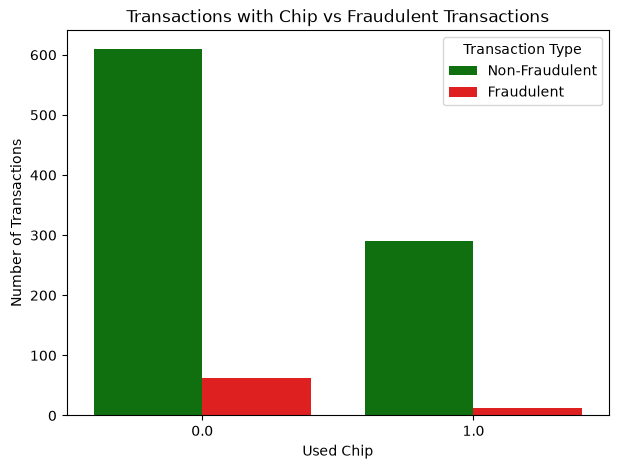

In [33]:
# Transactions with Chip vs Fraudulent Transactions
plt.figure(figsize=(7, 5))
sns.countplot(x='used_chip', hue='fraud', data=transactions_cleaned_df,
              palette={0: 'green', 1: 'red'})
plt.title('Transactions with Chip vs Fraudulent Transactions')
plt.xlabel('Used Chip')
plt.ylabel('Number of Transactions')
plt.legend(title='Transaction Type', labels=['Non-Fraudulent', 'Fraudulent'])
plt.show()

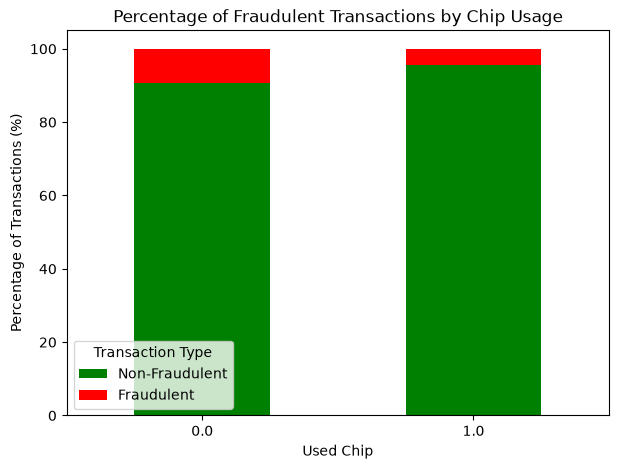

In [32]:
# Percentage of Fraudulent Transactions by Chip Usage
chip_fraud_pct = pd.crosstab(transactions_cleaned_df['used_chip'],
                             transactions_cleaned_df['fraud'],
                             normalize='index') * 100

chip_fraud_pct.plot(kind='bar', stacked=True, color=['green', 'red'], figsize=(7, 5))
plt.title('Percentage of Fraudulent Transactions by Chip Usage')
plt.xlabel('Used Chip')
plt.ylabel('Percentage of Transactions (%)')
plt.xticks(rotation=0)
plt.legend(title='Transaction Type', labels=['Non-Fraudulent', 'Fraudulent'])
plt.show()

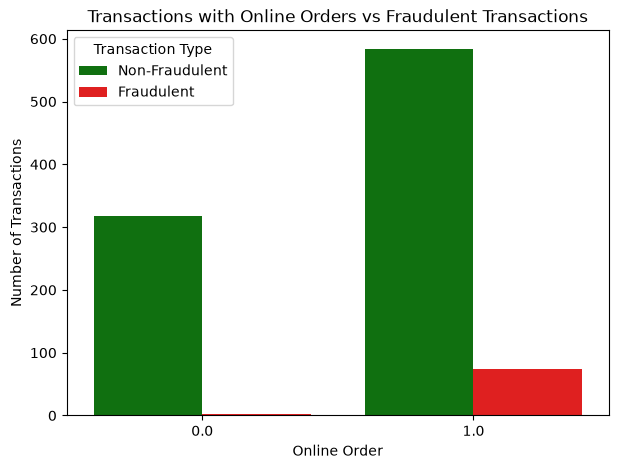

In [31]:
# Transactions with Online Orders vs Fraudulent Transactions
plt.figure(figsize=(7, 5))
sns.countplot(x='online_order', hue='fraud', data=transactions_cleaned_df,
              palette={0: 'green', 1: 'red'})
plt.title('Transactions with Online Orders vs Fraudulent Transactions')
plt.xlabel('Online Order')
plt.ylabel('Number of Transactions')
plt.legend(title='Transaction Type', labels=['Non-Fraudulent', 'Fraudulent'])
plt.show()

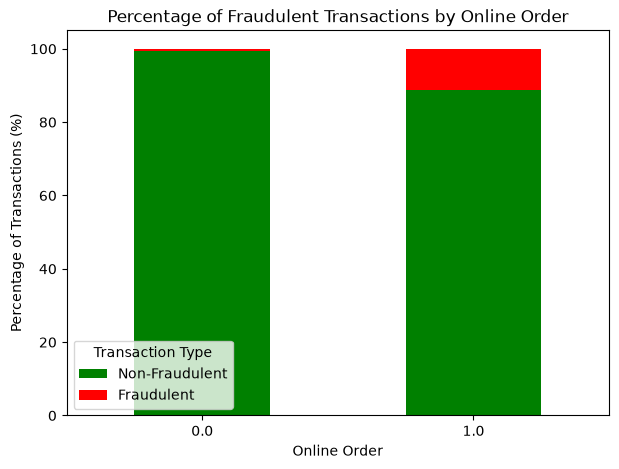

In [30]:
# Percentage of Fraudulent Transactions by Online Order
online_fraud_pct = pd.crosstab(transactions_cleaned_df['online_order'],
                               transactions_cleaned_df['fraud'],
                               normalize='index') * 100

online_fraud_pct.plot(kind='bar', stacked=True, color=['green', 'red'], figsize=(7, 5))
plt.title('Percentage of Fraudulent Transactions by Online Order')
plt.xlabel('Online Order')
plt.ylabel('Percentage of Transactions (%)')
plt.xticks(rotation=0)
plt.legend(title='Transaction Type', labels=['Non-Fraudulent', 'Fraudulent'])
plt.show()

## Scatterplots
Finally, we look at two numeric features together, using color to show fraud status (green = non-fraudulent, red = fraudulent). Both plots put `ratio_to_median_purchase_price` on the y axis, first against distance from the last transaction and then against distance from home.

**Prompt:** Moving forward, create a scatterplot to show the breakdown of fraudulent and non-0fraudulent transactions for distance_from_last_transaction vs ratio_to_median_purchase_price. And then do the same for distance_from_home vs ratio_to_median_purchase_price.


**AI:** Claude Sonnet 5.5

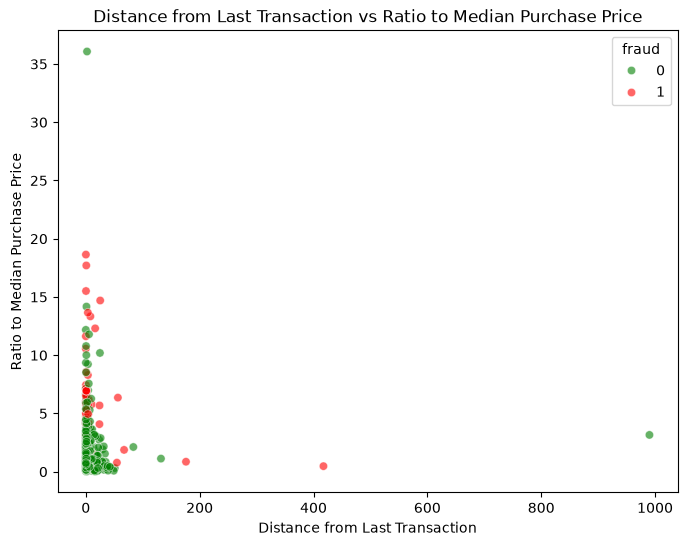

In [37]:
# Distance from Last Transaction vs Ratio to Median Purchase Price
plt.figure(figsize=(8, 6))
sns.scatterplot(x='distance_from_last_transaction', y='ratio_to_median_purchase_price',
                hue='fraud', data=transactions_cleaned_df,
                palette={0: 'green', 1: 'red'}, alpha=0.6)
plt.title('Distance from Last Transaction vs Ratio to Median Purchase Price')
plt.xlabel('Distance from Last Transaction')
plt.ylabel('Ratio to Median Purchase Price')
plt.show()

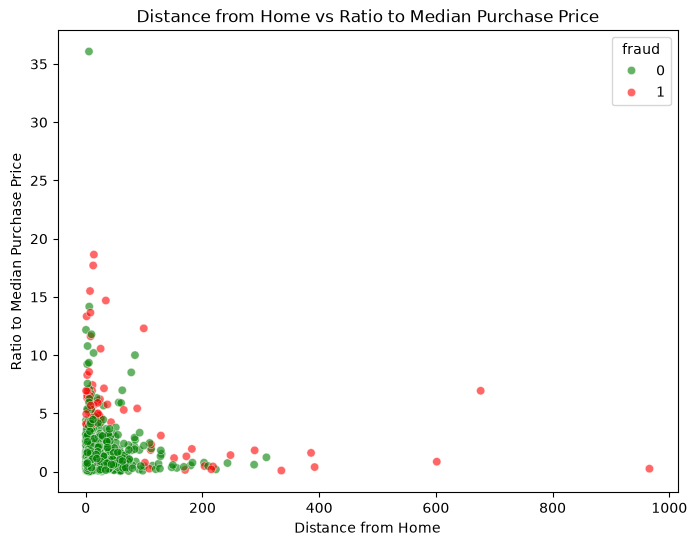

In [38]:
# Distance from Home vs Ratio to Median Purchase Price
plt.figure(figsize=(8, 6))
sns.scatterplot(x='distance_from_home', y='ratio_to_median_purchase_price',
                hue='fraud', data=transactions_cleaned_df,
                palette={0: 'green', 1: 'red'}, alpha=0.6)
plt.title('Distance from Home vs Ratio to Median Purchase Price')
plt.xlabel('Distance from Home')
plt.ylabel('Ratio to Median Purchase Price')
plt.show()

**Prompt:** Finally, using the code and results we developed, create markdown for each of the following:
    - A title and short introduction
    - A Data Context section with a table describing each column in the dataset
    - A header and explanation for each step in the process (loading the data, inspecing the data, data wrangling, visualizations)
    - A short explanation justifying why dropping null values is fine in this example (very few null values)


**AI:** Claude Sonnet 5.5